<a href="https://colab.research.google.com/github/bek180/computer-vision-projects/blob/main/Gabor_Grid_Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
from google.colab import drive
import cv2
import numpy as np

drive.mount("/content/drive")

project = Path("/content/drive/MyDrive/Gabor_Grid_Research")
project.mkdir(parents=True, exist_ok=True)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Папка доступна:", project.is_dir())

Mounted at /content/drive
OpenCV: 4.14.0
NumPy: 2.4.6
Папка доступна: True


samples.json:   0%|          | 0.00/2.61M [00:00<?, ?B/s]

data/data_50/189-14.png: reconstructing file:   0%|          |  0.00B /  508kB            

data/data_50/162-14.png: reconstructing file:   0%|          |  0.00B /  474kB            

data/data_50/002-97.png: reconstructing file:   0%|          |  0.00B /  474kB            

data/data_50/176-14.png: reconstructing file:   0%|          |  0.00B /  477kB            

data/data_50/189-14.png: downloading bytes:           |  0.00B            

... (790 outputs left out)

fields/defect_mask/defect_mask_12/008_ma(…): downloading bytes:           |  0.00B            

fields/defect_mask/defect_mask_12/009_ma(…): reconstructing file:   0%|          |  0.00B / 5.51kB            

fields/defect_mask/defect_mask_12/009_ma(…): downloading bytes:           |  0.00B            

Training images: 264
Test images: 78
Defect masks: 57


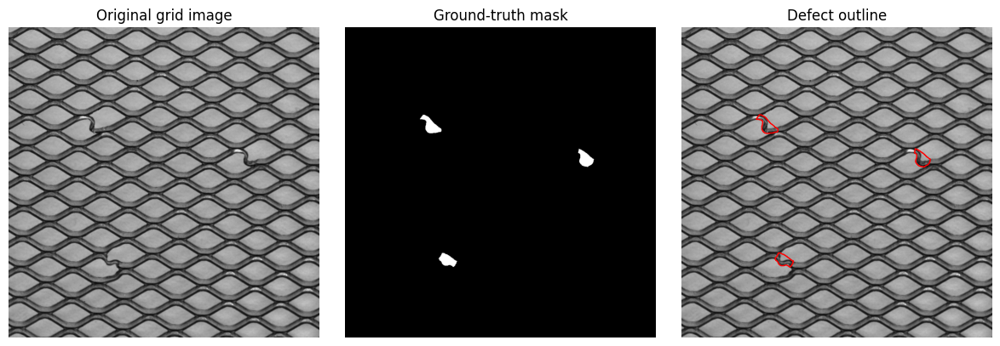

In [ ]:
import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm

repo = "Voxel51/mvtec-ad"
grid_dir = project / "grid"
grid_dir.mkdir(exist_ok=True)


def fetch(remote_path):
    return Path(
        hf_hub_download(
            repo_id=repo,
            repo_type="dataset",
            filename=remote_path,
        )
    )


# Read the dataset catalog and select the grid category.
catalog = json.loads(fetch("samples.json").read_text())["samples"]
samples = [s for s in catalog if s["category"]["label"] == "grid"]


def save_file(remote_path, destination):
    # Skip files that were saved during a previous run.
    if destination.is_file() and destination.stat().st_size > 0:
        return

    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(".part")
    temporary.write_bytes(fetch(remote_path).read_bytes())
    temporary.replace(destination)


def download_sample(s):
    split = s["split"]
    defect = s["defect"]["label"]
    name = Path(s["filepath"]).name
    save_file(s["filepath"], grid_dir / split / defect / name)

    # Save the corresponding mask for each defective test image.
    if split == "test" and defect != "good":
        mask_path = s["defect_mask"]["mask_path"]
        save_file(mask_path, grid_dir / "ground_truth" / defect / name)


with ThreadPoolExecutor(max_workers=4) as pool:
    list(tqdm(
        pool.map(download_sample, samples),
        total=len(samples),
        desc="Downloading grid samples",
    ))

train_files = sorted((grid_dir / "train").glob("*/*.png"))
test_files = sorted((grid_dir / "test").glob("*/*.png"))
mask_files = sorted((grid_dir / "ground_truth").glob("*/*.png"))

print("Training images:", len(train_files))
print("Test images:", len(test_files))
print("Defect masks:", len(mask_files))

assert len(train_files) == 264, "Expected 264 training images."
assert len(test_files) == 78, "Expected 78 test images."
assert mask_files, "No defect masks were found."

# Load one test image and its corresponding ground-truth mask.
mask_file = mask_files[0]
photo_file = grid_dir / "test" / mask_file.parent.name / mask_file.name

photo = cv2.imread(str(photo_file), cv2.IMREAD_GRAYSCALE)
mask = cv2.imread(str(mask_file), cv2.IMREAD_GRAYSCALE)

assert photo is not None, f"Could not read the test image: {photo_file}"
assert mask is not None, f"Could not read the defect mask: {mask_file}"
assert photo.shape == mask.shape, "The image and mask dimensions do not match."
assert mask.max() > 0, "The mask contains no defect pixels."

# Display the image, the binary mask, and the defect outline.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax in axes:
    ax.axis("off")

axes[0].imshow(photo, cmap="gray")
axes[0].set_title("Original grid image")

axes[1].imshow(mask > 0, cmap="gray")
axes[1].set_title("Ground-truth mask")

axes[2].imshow(photo, cmap="gray")
axes[2].contour(mask > 0, levels=[0.5], colors="red", linewidths=1)
axes[2].set_title("Defect outline")

plt.tight_layout()
plt.show()

Fitting normal texture model:   0%|          | 0/212 [00:00<?, ?it/s]

Calibrating threshold:   0%|          | 0/52 [00:00<?, ?it/s]

Model fitting images: 212
Threshold calibration images: 52
Fixed Gabor threshold: 2.0136


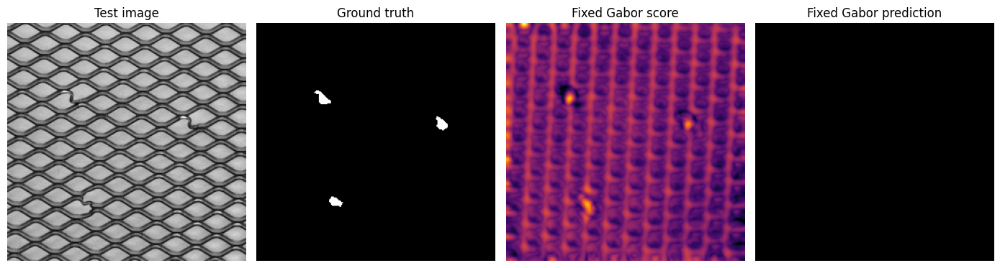

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Use the same image size and data split for both methods.
image_size = 256
rng = np.random.default_rng(42)
normal_files = sorted((grid_dir / "train" / "good").glob("*.png"))
assert len(normal_files) == 264, "Expected 264 normal training images."

order = rng.permutation(len(normal_files))
fit_files = [normal_files[i] for i in order[:212]]
calibration_files = [normal_files[i] for i in order[212:]]

def read_gray(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not read image: {path}")
    image = cv2.resize(image, (image_size, image_size), interpolation=cv2.INTER_AREA)
    return image.astype(np.float32) / 255.0

# Fix four filters before evaluation: two wavelengths and two orientations.
fixed_bank = [(w, a) for w in (8, 16) for a in (0, np.pi / 2)]

def make_kernels(bank):
    kernels = []
    for wavelength, angle in bank:
        sigma = 0.5 * wavelength
        side = 2 * int(np.ceil(3 * sigma)) + 1
        pair = []
        for phase in (0, np.pi / 2):
            kernel = cv2.getGaborKernel(
                (side, side), sigma, angle, wavelength, 1.0, phase, ktype=cv2.CV_32F
            )
            kernel -= kernel.mean()
            kernel /= max(float(np.linalg.norm(kernel)), 1e-8)
            pair.append(kernel)
        kernels.append(pair)
    return kernels

def energy_maps(image, kernels):
    maps = []
    for even, odd in kernels:
        real = cv2.filter2D(image, cv2.CV_32F, even)
        imag = cv2.filter2D(image, cv2.CV_32F, odd)
        energy = cv2.magnitude(real, imag)
        maps.append(cv2.GaussianBlur(energy, (0, 0), 2.0))
    return np.stack(maps)

def fit_model(files, kernels):
    samples = []
    for path in tqdm(files, desc="Fitting normal texture model"):
        maps = energy_maps(read_gray(path), kernels)
        samples.append(maps[:, ::8, ::8].reshape(len(kernels), -1))
    values = np.concatenate(samples, axis=1)
    center = np.median(values, axis=1)
    mad = np.median(np.abs(values - center[:, None]), axis=1)
    scale = np.maximum(1.4826 * mad, 1e-6)
    return center, scale

def anomaly_map(image, kernels, model):
    center, scale = model
    maps = energy_maps(image, kernels)
    deviations = np.abs(maps - center[:, None, None]) / scale[:, None, None]
    return deviations.mean(axis=0)

fixed_kernels = make_kernels(fixed_bank)
fixed_model = fit_model(fit_files, fixed_kernels)

scores = []
for path in tqdm(calibration_files, desc="Calibrating threshold"):
    score = anomaly_map(read_gray(path), fixed_kernels, fixed_model)
    scores.append(score.ravel())

fixed_threshold = float(np.percentile(np.concatenate(scores), 99))
print("Model fitting images:", len(fit_files))
print("Threshold calibration images:", len(calibration_files))
print("Fixed Gabor threshold:", round(fixed_threshold, 4))

# Show the same test image used in the previous cell.
image = read_gray(photo_file)
truth = cv2.resize(mask, (image_size, image_size), interpolation=cv2.INTER_NEAREST) > 0
score = anomaly_map(image, fixed_kernels, fixed_model)
prediction = score > fixed_threshold

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Test image")
axes[1].imshow(truth, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground truth")
axes[2].imshow(score, cmap="inferno")
axes[2].set_title("Fixed Gabor score")
axes[3].imshow(prediction, cmap="gray", vmin=0, vmax=1)
axes[3].set_title("Fixed Gabor prediction")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Estimating the normal texture spectrum:   0%|          | 0/212 [00:00<?, ?it/s]

FFT-selected filters:
Filter 1: wavelength=21.87 px, angle=70.0 deg
Filter 2: wavelength=21.26 px, angle=131.6 deg
Filter 3: wavelength=21.95 px, angle=31.0 deg
Filter 4: wavelength=21.19 px, angle=155.6 deg


Fitting normal texture model:   0%|          | 0/212 [00:00<?, ?it/s]

Calibrating FFT-Gabor threshold:   0%|          | 0/52 [00:00<?, ?it/s]

FFT-Gabor threshold: 1.6982
Ground-truth defect pixels: 344
Fixed Gabor predicted pixels: 0
FFT-Gabor predicted pixels: 0
Fixed Gabor correctly detected defect pixels: 0
FFT-Gabor correctly detected defect pixels: 0


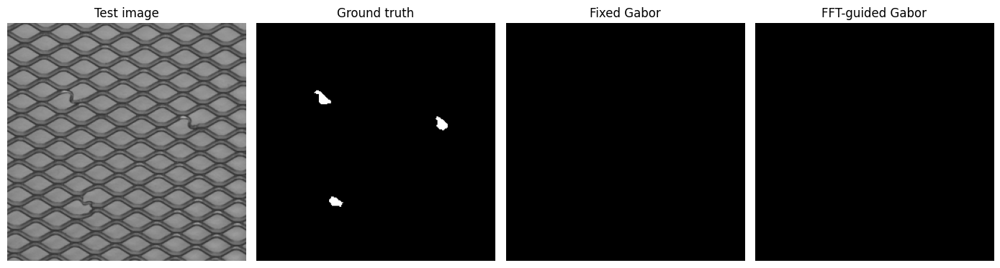

In [ ]:
# Estimate the average power spectrum using only normal fitting images.
window = np.outer(np.hanning(image_size), np.hanning(image_size))
power = np.zeros((image_size, image_size), dtype=np.float64)

for path in tqdm(fit_files, desc="Estimating the normal texture spectrum"):
    normal = read_gray(path)
    centered = (normal - normal.mean()) * window
    spectrum = np.fft.fft2(centered)
    power += np.abs(spectrum) ** 2

power /= len(fit_files)

# Search one half of the spectrum to avoid conjugate duplicates.
freq = np.fft.fftfreq(image_size)
fx, fy = np.meshgrid(freq, freq)
radius = np.hypot(fx, fy)
half_plane = (fy > 0) | ((fy == 0) & (fx > 0))

# Search wavelengths from 4 to 32 pixels at the working resolution.
valid = half_plane & (radius >= 1 / 32) & (radius <= 1 / 4)
candidates = np.where(valid, power, -np.inf)
fft_bank = []

for _ in range(len(fixed_bank)):
    row, col = np.unravel_index(np.argmax(candidates), candidates.shape)
    assert np.isfinite(candidates[row, col]), "No frequency candidates remain."

    peak_x, peak_y = fx[row, col], fy[row, col]
    wavelength = 1.0 / radius[row, col]
    angle = np.arctan2(peak_y, peak_x) % np.pi
    fft_bank.append((float(wavelength), float(angle)))

    # Suppress nearby bins around the peak and its conjugate.
    distance = np.minimum(
        np.hypot(fx - peak_x, fy - peak_y),
        np.hypot(fx + peak_x, fy + peak_y),
    )
    candidates[distance <= 3 / image_size] = -np.inf

print("FFT-selected filters:")
for i, (wavelength, angle) in enumerate(fft_bank, start=1):
    print(f"Filter {i}: wavelength={wavelength:.2f} px, angle={np.degrees(angle):.1f} deg")

# Reuse the baseline model-fitting procedure and calibration split.
fft_kernels = make_kernels(fft_bank)
fft_model = fit_model(fit_files, fft_kernels)

fft_calibration_scores = []
for path in tqdm(calibration_files, desc="Calibrating FFT-Gabor threshold"):
    calibration_score = anomaly_map(read_gray(path), fft_kernels, fft_model)
    fft_calibration_scores.append(calibration_score.ravel())

fft_threshold = float(np.percentile(np.concatenate(fft_calibration_scores), 99))
print(f"FFT-Gabor threshold: {fft_threshold:.4f}")

# Compare both predictions on the same example using frozen thresholds.
example = read_gray(photo_file)
fixed_score = anomaly_map(example, fixed_kernels, fixed_model)
fft_score = anomaly_map(example, fft_kernels, fft_model)
fixed_pred = fixed_score > fixed_threshold
fft_pred = fft_score > fft_threshold

print("Ground-truth defect pixels:", int(truth.sum()))
print("Fixed Gabor predicted pixels:", int(fixed_pred.sum()))
print("FFT-Gabor predicted pixels:", int(fft_pred.sum()))
print("Fixed Gabor correctly detected defect pixels:", int((fixed_pred & truth).sum()))
print("FFT-Gabor correctly detected defect pixels:", int((fft_pred & truth).sum()))

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
panels = [
    (example, "Test image"),
    (truth, "Ground truth"),
    (fixed_pred, "Fixed Gabor"),
    (fft_pred, "FFT-guided Gabor"),
]
for ax, (panel, title) in zip(axes, panels):
    ax.imshow(panel, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
fig.savefig(project / "gabor_example_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd

methods = {
    "Fixed Gabor": (fixed_kernels, fixed_model, fixed_threshold),
    "FFT-guided Gabor": (fft_kernels, fft_model, fft_threshold),
}
brightness_levels = (0.7, 1.0, 1.3)

assert len(test_files) == 78, "Expected 78 test images."
assert sum(p.parent.name != "good" for p in test_files) == 57, (
    "Expected 57 defective test images."
)

records = []

for path in tqdm(test_files, desc="Evaluating both methods"):
    original = read_gray(path)
    defect_type = path.parent.name

    if defect_type == "good":
        target = np.zeros(original.shape, dtype=bool)
    else:
        mask_path = grid_dir / "ground_truth" / defect_type / path.name
        raw_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if raw_mask is None:
            raise FileNotFoundError(f"Could not read mask: {mask_path}")
        target = cv2.resize(
            raw_mask, (image_size, image_size), interpolation=cv2.INTER_NEAREST
        ) > 0

    for factor in brightness_levels:
        adjusted = np.clip(original * factor, 0.0, 1.0)

        for method, (kernels, model, threshold) in methods.items():
            scores = anomaly_map(adjusted, kernels, model)
            predicted = scores > threshold
            records.append({
                "Image": str(path.relative_to(grid_dir)),
                "Defect type": defect_type,
                "Brightness": factor,
                "Method": method,
                "TP": int(np.count_nonzero(predicted & target)),
                "FP": int(np.count_nonzero(predicted & ~target)),
                "FN": int(np.count_nonzero(~predicted & target)),
            })

per_image = pd.DataFrame(records)
assert len(per_image) == 78 * 3 * 2, "Incomplete evaluation."

summary = (
    per_image.groupby(["Brightness", "Method"], as_index=False)
    [["TP", "FP", "FN"]].sum()
)

tp, fp, fn = summary["TP"], summary["FP"], summary["FN"]
summary["Precision"] = tp / (tp + fp).replace(0, np.nan)
summary["Recall"] = tp / (tp + fn)
summary["F1"] = 2 * tp / (2 * tp + fp + fn)

comparison = summary.pivot(index="Brightness", columns="Method", values="F1")
comparison["FFT minus fixed"] = comparison["FFT-guided Gabor"] - comparison["Fixed Gabor"]
comparison.loc["Mean across conditions"] = comparison.mean()

per_image.to_csv(project / "grid_per_image_counts.csv", index=False)
summary.to_csv(project / "grid_pixel_metrics.csv", index=False)
comparison.to_csv(project / "grid_f1_comparison.csv")

print("Pixel-level results across all 78 test images")
print(summary.round(4).to_string(index=False))
print("\nF1 comparison")
print(comparison.round(4).to_string())

Evaluating both methods:   0%|          | 0/78 [00:00<?, ?it/s]

Pixel-level results across all 78 test images
 Brightness           Method   TP     FP    FN  Precision  Recall     F1
        0.7 FFT-guided Gabor    0      0 35280        NaN  0.0000 0.0000
        0.7      Fixed Gabor    0     83 35280     0.0000  0.0000 0.0000
        1.0 FFT-guided Gabor    0  12701 35280     0.0000  0.0000 0.0000
        1.0      Fixed Gabor  603  52298 34677     0.0114  0.0171 0.0137
        1.3 FFT-guided Gabor  693 255184 34587     0.0027  0.0196 0.0048
        1.3      Fixed Gabor 4191 399931 31089     0.0104  0.1188 0.0191

F1 comparison
Method                  FFT-guided Gabor  Fixed Gabor  FFT minus fixed
Brightness                                                            
0.7                               0.0000       0.0000           0.0000
1.0                               0.0000       0.0137          -0.0137
1.3                               0.0048       0.0191          -0.0143
Mean across conditions            0.0016       0.0109          -0.0093


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from tqdm.auto import tqdm

def load_test_mask(path):
    if path.parent.name == "good":
        return np.zeros((image_size, image_size), dtype=bool)

    mask_path = grid_dir / "ground_truth" / path.parent.name / path.name
    raw = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if raw is None:
        raise FileNotFoundError(f"Could not read mask: {mask_path}")
    return cv2.resize(
        raw, (image_size, image_size), interpolation=cv2.INTER_NEAREST
    ) > 0

test_images = np.stack([read_gray(path) for path in test_files])
test_masks = np.stack([load_test_mask(path) for path in test_files])
assert len(test_images) == 78 and test_masks.sum() == 35280, (
    "Test data differ from the original F1 experiment."
)

def evaluate_scores(model_specs, preprocess, variant):
    labels = test_masks.ravel()
    prevalence = float(labels.mean())
    rows = []

    for factor in brightness_levels:
        # Apply brightness changes before any normalization.
        images = [
            preprocess(np.clip(image * factor, 0.0, 1.0))
            for image in test_images
        ]

        for name, (kernels, model, threshold) in model_specs.items():
            maps = np.stack([
                anomaly_map(image, kernels, model)
                for image in tqdm(images, desc=f"{variant} | {name} | {factor}")
            ])
            scores = maps.ravel()
            assert np.isfinite(scores).all(), "Non-finite anomaly scores."

            pred = scores > threshold
            tp = int(np.count_nonzero(pred & labels))
            fp = int(np.count_nonzero(pred & ~labels))
            fn = int(labels.sum()) - tp

            rows.append({
                "Variant": variant,
                "Brightness": factor,
                "Method": name,
                "TP": tp, "FP": fp, "FN": fn,
                "F1": 2 * tp / (2 * tp + fp + fn),
                "AP": average_precision_score(labels, scores),
                "Prevalence": prevalence,
            })

    return pd.DataFrame(rows)

raw_results = evaluate_scores(methods, lambda image: image, "Original")

# Verify exact agreement with the previous experiment before interpreting AP.
keys = ["Brightness", "Method"]
counts = ["TP", "FP", "FN"]
old_counts = summary.set_index(keys)[counts].sort_index()
new_counts = raw_results.set_index(keys)[counts].sort_index()
assert old_counts.equals(new_counts), "Counts differ from the original experiment."

raw_results.to_csv(project / "grid_original_ap.csv", index=False)
print(raw_results[["Brightness", "Method", "F1", "AP", "Prevalence"]]
      .round(5).to_string(index=False))

Original | Fixed Gabor | 0.7:   0%|          | 0/78 [00:00<?, ?it/s]

Original | FFT-guided Gabor | 0.7:   0%|          | 0/78 [00:00<?, ?it/s]

Original | Fixed Gabor | 1.0:   0%|          | 0/78 [00:00<?, ?it/s]

Original | FFT-guided Gabor | 1.0:   0%|          | 0/78 [00:00<?, ?it/s]

Original | Fixed Gabor | 1.3:   0%|          | 0/78 [00:00<?, ?it/s]

Original | FFT-guided Gabor | 1.3:   0%|          | 0/78 [00:00<?, ?it/s]

 Brightness           Method      F1      AP  Prevalence
        0.7      Fixed Gabor 0.00000 0.00728      0.0069
        0.7 FFT-guided Gabor 0.00000 0.01625      0.0069
        1.0      Fixed Gabor 0.01368 0.00816      0.0069
        1.0 FFT-guided Gabor 0.00000 0.00711      0.0069
        1.3      Fixed Gabor 0.01908 0.00894      0.0069
        1.3 FFT-guided Gabor 0.00476 0.00596      0.0069


In [ ]:
def normalize_brightness(image):
    mean = float(image.mean())
    std = float(image.std())
    return ((image - mean) / max(std, 1e-6)).astype(np.float32)

def fit_normalized_model(kernels):
    samples = []
    for path in tqdm(fit_files, desc="Fitting normalized texture model"):
        image = normalize_brightness(read_gray(path))
        maps = energy_maps(image, kernels)
        samples.append(maps[:, ::8, ::8].reshape(len(kernels), -1))

    values = np.concatenate(samples, axis=1)
    center = np.median(values, axis=1)
    mad = np.median(np.abs(values - center[:, None]), axis=1)
    model = (center, np.maximum(1.4826 * mad, 1e-6))

    calibration_scores = []
    for path in tqdm(calibration_files, desc="Calibrating normalized threshold"):
        image = normalize_brightness(read_gray(path))
        calibration_scores.append(anomaly_map(image, kernels, model).ravel())

    threshold = float(np.percentile(np.concatenate(calibration_scores), 99))
    return model, threshold

normalized_methods = {}
for name, (kernels, _, _) in methods.items():
    model, threshold = fit_normalized_model(kernels)
    normalized_methods[name] = (kernels, model, threshold)
    print(f"{name} normalized threshold: {threshold:.5f}")

normalized_results = evaluate_scores(
    normalized_methods, normalize_brightness, "Normalized"
)

all_results = pd.concat([raw_results, normalized_results], ignore_index=True)
all_results.to_csv(project / "grid_normalization_comparison.csv", index=False)

table = all_results.pivot(
    index=["Brightness", "Method"], columns="Variant", values=["F1", "AP"]
)
print("\nOriginal and normalized results")
print(table.round(5).to_string())

means = all_results.groupby(["Method", "Variant"])[["F1", "AP"]].mean()
print("\nMean across three brightness conditions")
print(means.round(5).to_string())

Fitting normalized texture model:   0%|          | 0/212 [00:00<?, ?it/s]

Calibrating normalized threshold:   0%|          | 0/52 [00:00<?, ?it/s]

Fixed Gabor normalized threshold: 1.85678


Fitting normalized texture model:   0%|          | 0/212 [00:00<?, ?it/s]

Calibrating normalized threshold:   0%|          | 0/52 [00:00<?, ?it/s]

FFT-guided Gabor normalized threshold: 1.29529


... (3 outputs left out)

Normalized | FFT-guided Gabor | 1.0:   0%|          | 0/78 [00:00<?, ?it/s]

Normalized | Fixed Gabor | 1.3:   0%|          | 0/78 [00:00<?, ?it/s]

Normalized | FFT-guided Gabor | 1.3:   0%|          | 0/78 [00:00<?, ?it/s]


Original and normalized results
                                    F1                  AP         
Variant                     Normalized Original Normalized Original
Brightness Method                                                  
0.7        FFT-guided Gabor    0.00260  0.00000    0.00686  0.01625
           Fixed Gabor         0.01193  0.00000    0.00819  0.00728
1.0        FFT-guided Gabor    0.00260  0.00000    0.00686  0.00711
           Fixed Gabor         0.01193  0.01368    0.00819  0.00816
1.3        FFT-guided Gabor    0.00273  0.00476    0.00683  0.00596
           Fixed Gabor         0.01174  0.01908    0.00816  0.00894

Mean across three brightness conditions
                                  F1       AP
Method           Variant                     
FFT-guided Gabor Normalized  0.00264  0.00685
                 Original    0.00159  0.00977
Fixed Gabor      Normalized  0.01186  0.00818
                 Original    0.01092  0.00813
